<a href="https://colab.research.google.com/github/LuisTT0903/Processamento-de-Sinais1/blob/main/Pr%C3%A1tica7Quest%C3%A3o4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Q2 - Passa-faixa 6-8 kHz (cascata)
Ordem global: 4   Polos originais |p| = [0.8481 0.8481 0.8907 0.8907]
Sensibilidade dos polos (max_i sum_k |dp_i/da_k|): forma direta global = 5.49   blocos = 1.66
Coeficientes originais: b = [ 0.052749  0.       -0.105499  0.        0.052749]
                        a = [1.       2.071284 2.472305 1.541571 0.570598]

  forma   b    max|p|  estável  desloc. polos  erro máx passa [dB] Ganho máx f<4k ou f>9,5k [dB]
   orig   -   0.8907      sim       0.00e+00             0.00e+00                       -22.14
 global   2  1.543689      NÃO       7.13e-01             2.24e+01                       -20.87  (instável: resposta em frequência sem significado físico)
 global   4  1.000000    marg.       1.98e-01             6.41e+01                       -22.58  (polo sobre o círculo unitário: marginalmente estável)
 global   8  0.881668      sim       1.61e-02             7.89e-01                       -22.14
 global  16  0.890600      sim       1.48e-04     

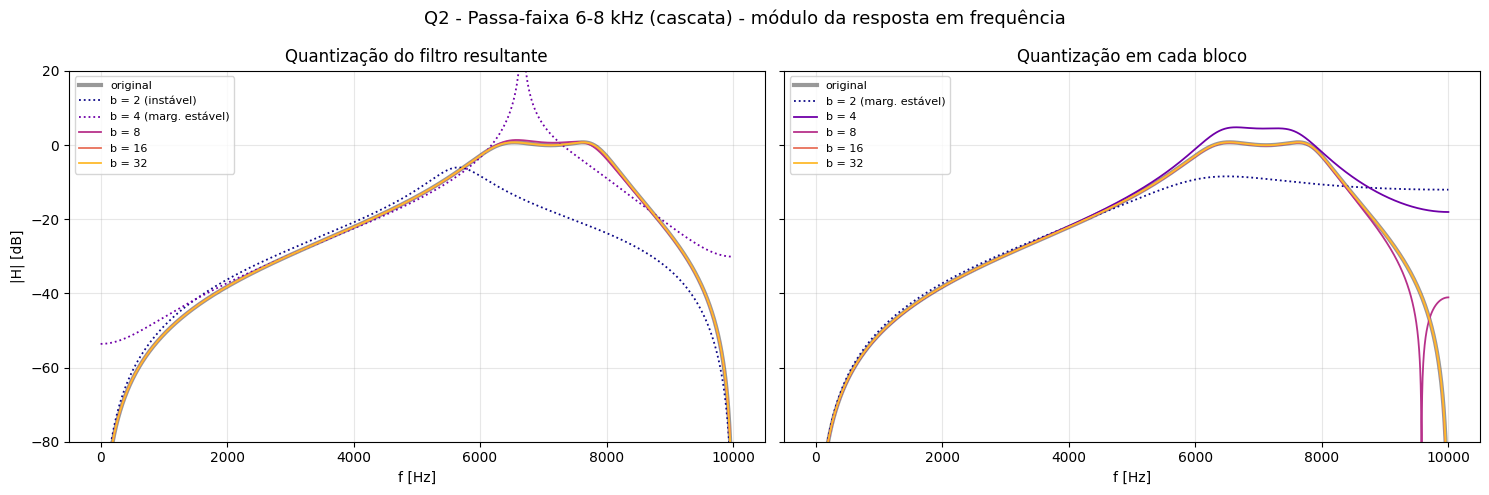

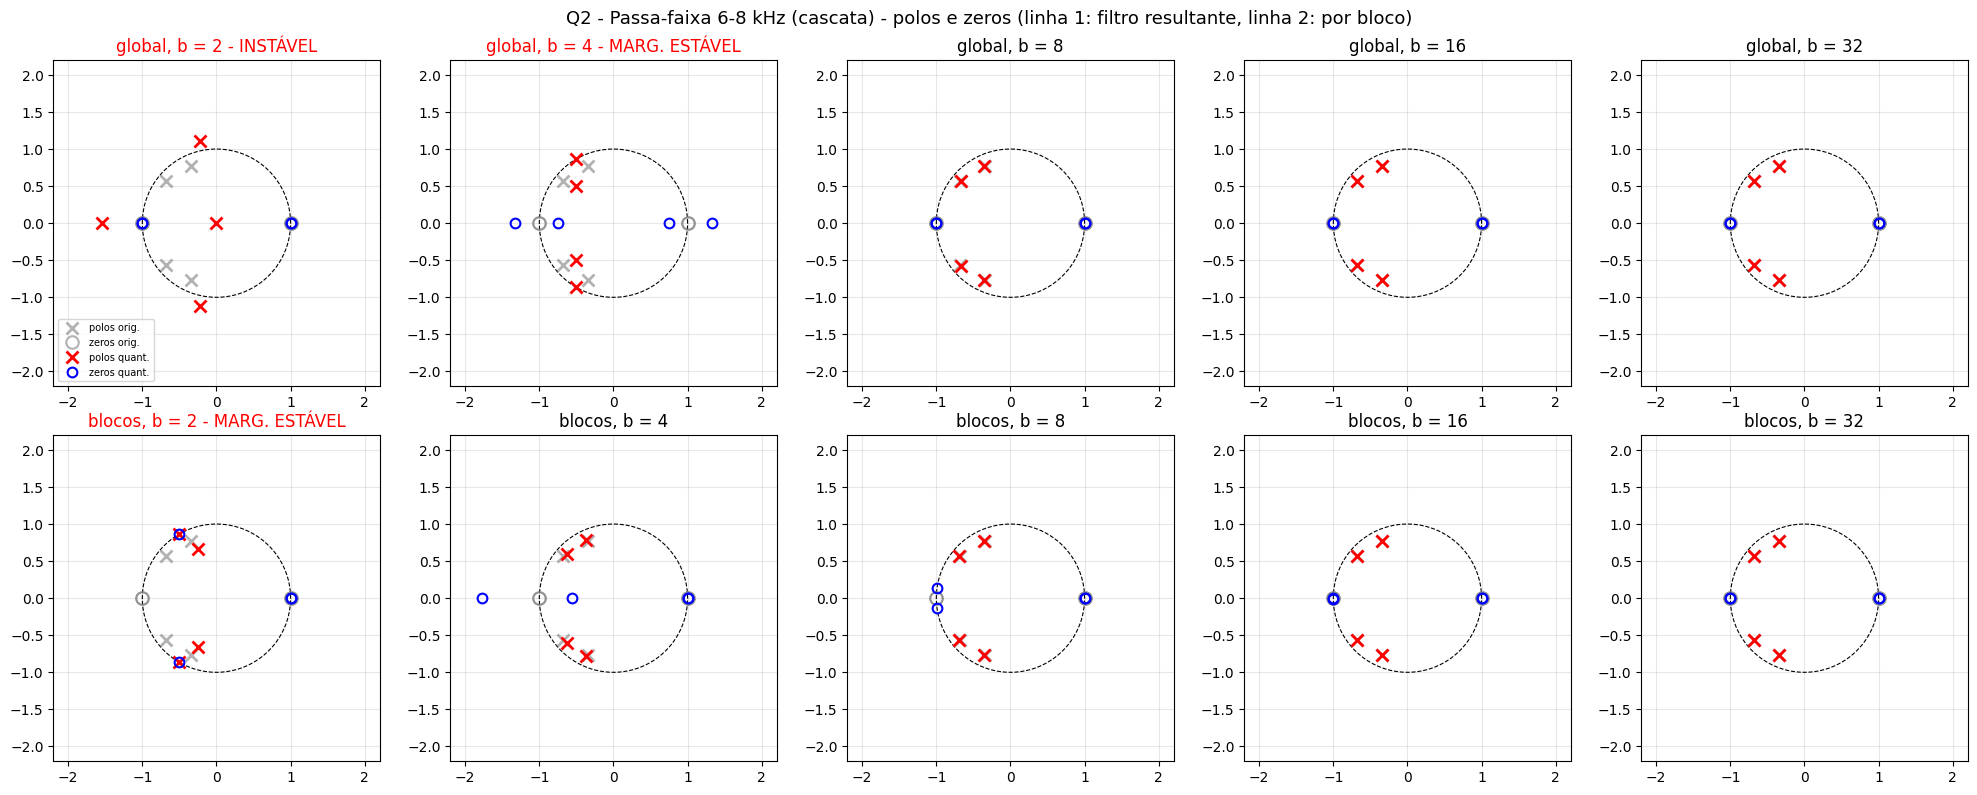

Q3 - Rejeita-faixa 1-4 kHz (paralelo)
Ordem global: 8   Polos originais |p| = [0.5093 0.5093 0.8841 0.8841 0.8904 0.8904 0.9494 0.9494]
Sensibilidade dos polos (max_i sum_k |dp_i/da_k|): forma direta global = 221.63   blocos = 8.42
Coeficientes originais: b = [-0.101246  0.769651 -2.559317  4.886506 -5.843997  4.491134 -2.162793
  0.597671 -0.072427]
                        a = [ 1.       -3.486657  5.370143 -5.182086  3.558913 -1.669743  0.670998
 -0.401293  0.144909]

  forma   b    max|p|  estável  desloc. polos  erro máx passa [dB]     Ganho máx 1,5-3 kHz [dB]
   orig   -   0.9494      sim       0.00e+00             0.00e+00                       -22.54
 global   2  2.946965      NÃO       5.09e-01             5.31e+01                        -1.18  (instável: resposta em frequência sem significado físico)
 global   4  1.312282      NÃO       6.73e-01             7.01e+01                        16.69  (instável: resposta em frequência sem significado físico)
 global   8  1.000000   

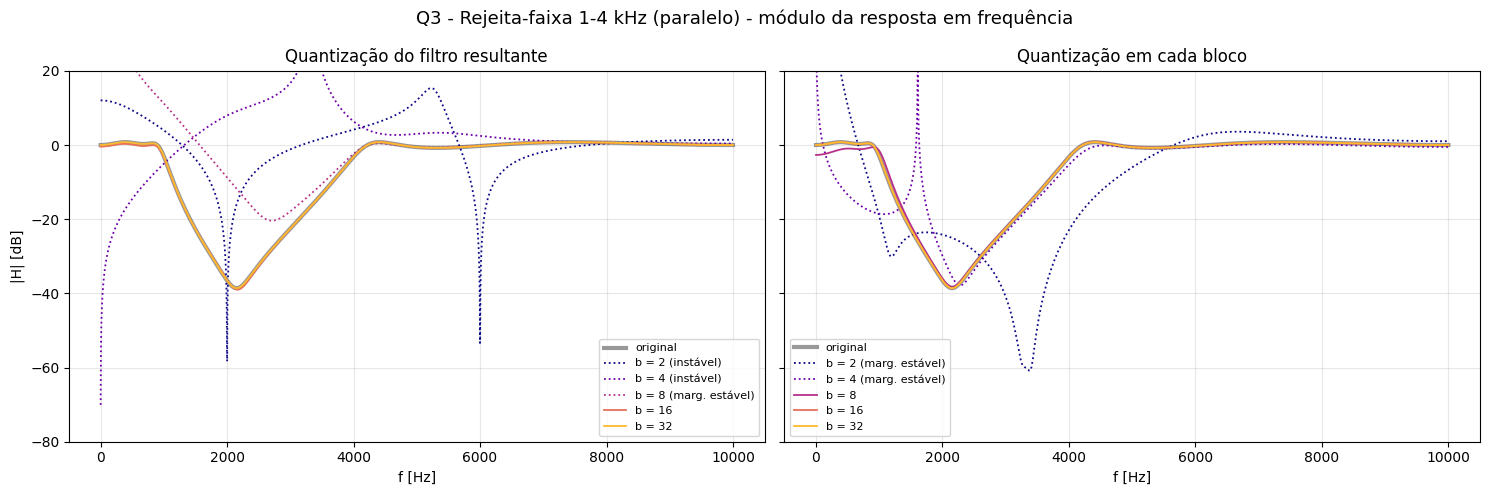

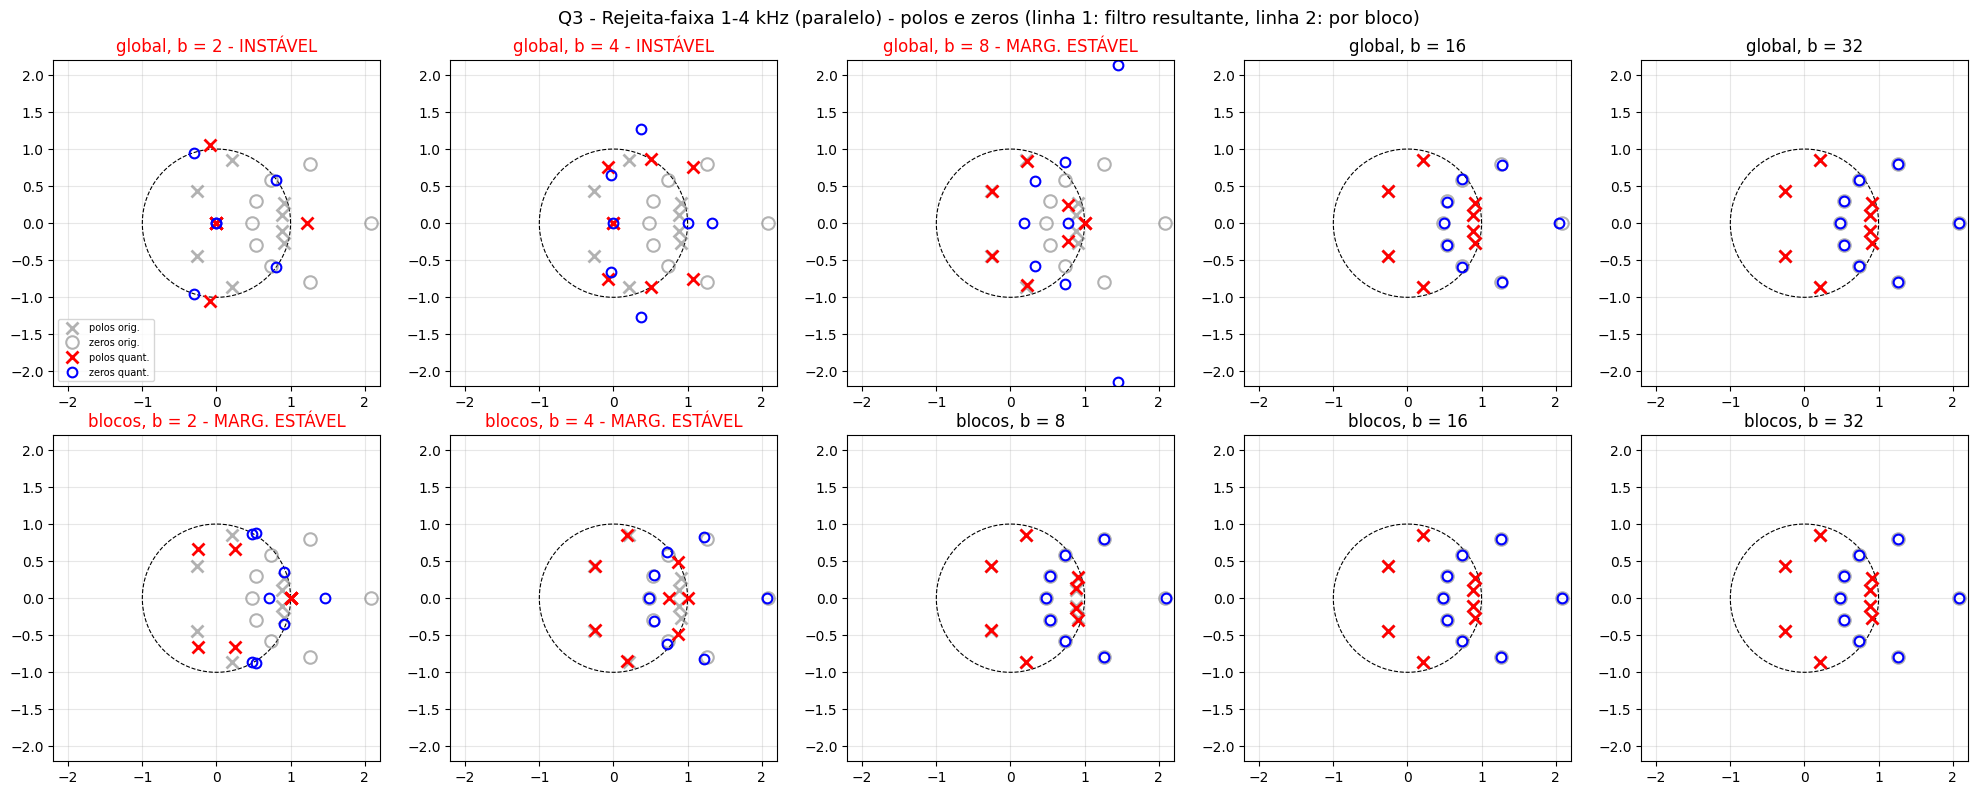

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fs = 20000
bits = [2, 4, 8, 16, 32]
f = np.linspace(1, fs / 2 - 1, 4000)
zf = np.exp(2j * np.pi * f / fs)

x_q2 = [6353.6424143350405, 0.8480539495767644, 7796.970716829073, 0.8907209399022651]
x_q3 = [402.15201321807507, 0.890426440942112, 922.3751028963356, 0.9494147418340095,
        6720.477773809696, 0.5093000295323866, 4228.365927834187, 0.8841383662027695]


def bloco(tipo, fp, r, f_norm=None):
    th = 2 * np.pi * fp / fs
    a = np.array([1.0, -2 * r * np.cos(th), r ** 2])
    if tipo == "pb":
        b = np.array([1.0, 2.0, 1.0])
        g = np.polyval(a, 1.0) / np.polyval(b, 1.0)
    elif tipo == "pa":
        b = np.array([1.0, -2.0, 1.0])
        g = np.polyval(a, -1.0) / np.polyval(b, -1.0)
    if f_norm is not None:
        z0 = np.exp(2j * np.pi * f_norm / fs)
        g = abs(np.polyval(a, z0) / np.polyval(b, z0))
    return g * b, a


def quantiza(c, b, monico=False):
    c = np.asarray(c, float)
    q = c.copy()
    idx = slice(1, None) if monico else slice(None)
    v = c[idx]
    m = np.max(np.abs(v))
    if m == 0:
        return q
    inteiros = int(np.floor(np.log2(m))) + 1
    passo = 2.0 ** (inteiros - (b - 1))
    vq = np.round(v / passo) * passo
    vq = np.clip(vq, -2.0 ** inteiros, 2.0 ** inteiros - passo)
    q[idx] = vq
    return q


def quantiza_ba(b_, a_, nb):
    return quantiza(b_, nb), quantiza(a_, nb, monico=True)


def resp_ba(b_, a_):
    return np.polyval(b_, zf) / np.polyval(a_, zf)


def db(H):
    return 20 * np.log10(np.abs(H) + 1e-12)


def sensibilidade(a_):
    p = np.roots(a_)
    N = len(p)
    s = []
    for i in range(N):
        den = np.prod([abs(p[i] - p[j]) for j in range(N) if j != i])
        s.append(sum(abs(p[i]) ** (N - k) for k in range(1, N + 1)) / den)
    return max(s)


def desloc_polos(p0, p1):
    if len(p1) == 0:
        return np.nan
    return max(np.min(np.abs(p1 - p)) for p in p0)


class Filtro:
    def __init__(self, nome, blocos, combina, regiao_passa, regiao_rejeita, nome_rej):
        self.nome = nome
        self.blocos = blocos
        self.combina = combina
        self.passa = regiao_passa
        self.rejeita = regiao_rejeita
        self.nome_rej = nome_rej
        self.b, self.a = combina(blocos)

    def global_q(self, nb):
        return quantiza_ba(self.b, self.a, nb)

    def blocos_q(self, nb):
        bq = [quantiza_ba(b_, a_, nb) for b_, a_ in self.blocos]
        return self.combina(bq), bq


def cascata(blocos):
    b_, a_ = np.array([1.0]), np.array([1.0])
    for bb, aa in blocos:
        b_ = np.convolve(b_, bb)
        a_ = np.convolve(a_, aa)
    return b_, a_


def paralelo_pb_menos_pa(blocos):
    b1, a1 = cascata(blocos[:2])
    b2, a2 = cascata(blocos[2:])
    return np.polysub(np.convolve(b1, a2), np.convolve(b2, a1)), np.convolve(a1, a2)


f0 = 7000
filtro2 = Filtro("Q2 - Passa-faixa 6-8 kHz (cascata)",
                 [bloco("pa", x_q2[0], x_q2[1], f0), bloco("pb", x_q2[2], x_q2[3], f0)],
                 cascata, (f >= 6000) & (f <= 8000), (f <= 4000) | (f >= 9500), "Ganho máx f<4k ou f>9,5k")
filtro3 = Filtro("Q3 - Rejeita-faixa 1-4 kHz (paralelo)",
                 [bloco("pb", x_q3[0], x_q3[1]), bloco("pb", x_q3[2], x_q3[3]),
                  bloco("pa", x_q3[4], x_q3[5]), bloco("pa", x_q3[6], x_q3[7])],
                 paralelo_pb_menos_pa, (f <= 1000) | (f >= 4000), (f >= 1500) & (f <= 3000), "Ganho máx 1,5-3 kHz")


def analisa(F):
    print("=" * 110)
    print(F.nome)
    print("=" * 110)
    H0 = resp_ba(F.b, F.a)
    d0 = db(H0)
    p0 = np.roots(F.a)
    z0 = np.roots(F.b)
    print(f"Ordem global: {len(F.a) - 1}   Polos originais |p| = {np.round(np.sort(np.abs(p0)), 4)}")
    print(f"Sensibilidade dos polos (max_i sum_k |dp_i/da_k|): forma direta global = {sensibilidade(F.a):.2f}   "
          f"blocos = {max(sensibilidade(a_) for _, a_ in F.blocos):.2f}")
    print(f"Coeficientes originais: b = {np.round(F.b, 6)}")
    print(f"                        a = {np.round(F.a, 6)}")
    print()
    cab = f"{'forma':>7} {'b':>3} {'max|p|':>9} {'estável':>8} {'desloc. polos':>14} {'erro máx passa [dB]':>20} {F.nome_rej + ' [dB]':>28}"
    print(cab)
    print(f"{'orig':>7} {'-':>3} {np.max(np.abs(p0)):>8.4f} {'sim':>8} {0:>14.2e} {0:>20.2e} {d0[F.rejeita].max():>28.2f}")
    resultados = {"global": [], "blocos": []}
    for forma in ["global", "blocos"]:
        for nb in bits:
            if forma == "global":
                bq, aq = F.global_q(nb)
                pq = np.roots(aq) if np.any(aq[1:] != 0) else np.array([])
            else:
                (bq, aq), bqs = F.blocos_q(nb)
                pq = np.concatenate([np.roots(aa) for _, aa in bqs])
            zq = np.roots(bq) if np.count_nonzero(bq) > 1 else np.array([])
            mp = np.max(np.abs(pq)) if len(pq) else 0.0
            est = mp < 1 - 1e-6
            marg = abs(mp - 1) <= 1e-6
            Hq = resp_ba(bq, aq)
            dq = db(Hq)
            erro = np.max(np.abs(dq[F.passa] - d0[F.passa]))
            rej = dq[F.rejeita].max()
            dp = desloc_polos(p0, pq)
            obs = "" if est else ("  (polo sobre o círculo unitário: marginalmente estável)" if marg else "  (instável: resposta em frequência sem significado físico)")
            rot = "sim" if est else ("marg." if marg else "NÃO")
            print(f"{forma:>7} {nb:>3} {mp:>9.6f} {rot:>8} {dp:>14.2e} {erro:>20.2e} {rej:>28.2f}{obs}")
            resultados[forma].append((nb, bq, aq, pq, zq, dq, rot))
    print()
    for nb in [4, 8]:
        (bqg, aqg) = F.global_q(nb)
        (_, _), bq_blocos = F.blocos_q(nb)
        print(f"Exemplo b = {nb}: global a_q = {aqg}")
        for i, (bb, aa) in enumerate(bq_blocos, 1):
            print(f"              bloco {i}: b_q = {bb}   a_q = {aa}")
    print()

    cores = plt.cm.plasma(np.linspace(0, 0.85, len(bits)))
    fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    for k, forma in enumerate(["global", "blocos"]):
        ax[k].plot(f, d0, "k", lw=3, alpha=0.4, label="original")
        for (nb, bq, aq, pq, zq, dq, rot), cor in zip(resultados[forma], cores):
            ax[k].plot(f, dq, color=cor, lw=1.3, ls="-" if rot == "sim" else ":",
                       label=f"b = {nb}" + {"sim": "", "marg.": " (marg. estável)", "NÃO": " (instável)"}[rot])
        ax[k].set_ylim(-80, 20)
        ax[k].set_xlabel("f [Hz]")
        ax[k].set_title(f"Quantização {'do filtro resultante' if forma == 'global' else 'em cada bloco'}")
        ax[k].grid(alpha=0.3)
        ax[k].legend(fontsize=8)
    ax[0].set_ylabel("|H| [dB]")
    fig.suptitle(F.nome + " - módulo da resposta em frequência", fontsize=13)
    fig.tight_layout()
    plt.show()

    t = np.linspace(0, 2 * np.pi, 400)
    fig, ax = plt.subplots(2, len(bits), figsize=(4 * len(bits), 8))
    for i, forma in enumerate(["global", "blocos"]):
        for j, (nb, bq, aq, pq, zq, dq, rot) in enumerate(resultados[forma]):
            a_ = ax[i, j]
            a_.plot(np.cos(t), np.sin(t), "k--", lw=0.8)
            a_.plot(p0.real, p0.imag, "x", color="gray", ms=9, mew=2, alpha=0.6, label="polos orig.")
            a_.plot(z0.real, z0.imag, "o", mfc="none", mec="gray", ms=9, mew=1.5, alpha=0.6, label="zeros orig.")
            if len(pq):
                a_.plot(pq.real, pq.imag, "rx", ms=9, mew=2, label="polos quant.")
            if len(zq):
                a_.plot(zq.real, zq.imag, "bo", mfc="none", ms=7, mew=1.5, label="zeros quant.")
            a_.set_aspect("equal")
            a_.set_xlim(-2.2, 2.2)
            a_.set_ylim(-2.2, 2.2)
            a_.grid(alpha=0.3)
            a_.set_title(f"{forma}, b = {nb}" + {"sim": "", "marg.": " - MARG. ESTÁVEL", "NÃO": " - INSTÁVEL"}[rot],
                         color="k" if rot == "sim" else "r")
            if i == 0 and j == 0:
                a_.legend(fontsize=7, loc="lower left")
    fig.suptitle(F.nome + " - polos e zeros (linha 1: filtro resultante, linha 2: por bloco)", fontsize=13)
    fig.tight_layout()
    plt.show()


analisa(filtro2)
analisa(filtro3)

Os coeficientes foram quantizados em ponto fixo com b bits. Cada vetor de coeficientes tem sua própria escala, uma potência de 2. Comparei duas formas: quantizar o filtro resultante na forma direta ou quantizar cada bloco de 2ª ordem separadamente.

A sensibilidade dos polos aos coeficientes já antecipa os resultados. Na questão 2 ela vale 5,5 na forma direta e 1,7 nos blocos. Na questão 3 vale 222 na forma direta e 8,4 nos blocos, porque o filtro de 8ª ordem tem vários polos próximos entre si e do círculo unitário.

No passa-faixas da questão 2, com 2 e 4 bits a forma direta fica instável ou com polos sobre o círculo, enquanto os blocos já são estáveis com 4 bits. Com 8 bits as duas formas funcionam, mas o erro na banda é de 0,79 dB na forma direta e 0,21 dB nos blocos. Com 16 e 32 bits as duas versões praticamente coincidem com a original.

No rejeita-faixas da questão 3, a forma direta é instável com 2 e 4 bits, marginalmente estável com 8 bits (aparece um polo em z = 1) e só funciona a partir de 16 bits. Por blocos, o filtro já é estável com 8 bits e mantém 21,7 dB de atenuação na faixa rejeitada.

Em resumo, quanto maior a ordem e mais agrupados os polos, maior a sensibilidade à quantização. Implementar o filtro em seções de 2ª ordem (em cascata ou em paralelo) preserva a estabilidade e a resposta com cerca de metade dos bits.